In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, HTML

output_dir = "./Output"

cross_path1 = rf"{output_dir}\Cross\best_model_MultiviewAttention_cross_20250601_122704.csv"
df_cross_res = pd.read_csv(cross_path1)

df_cross_with_test = df_cross_res.dropna(subset=['test_overall_accuracy'])


# Show the first 10 rows of the DataFrame in a scrollable box
display(HTML(df_cross_with_test.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

,trial_id,epoch,train_overall_accuracy,train_overall_F1,train_overall_recall,train_overall_precision,train_resting_accuracy,train_resting_F1,train_resting_recall,train_resting_precision,train_math_accuracy,train_math_F1,train_math_recall,train_math_precision,train_memory_accuracy,train_memory_F1,train_memory_recall,train_memory_precision,train_motor_accuracy,train_motor_F1,train_motor_recall,train_motor_precision,val_overall_accuracy,val_overall_F1,val_overall_recall,val_overall_precision,val_resting_accuracy,val_resting_F1,val_resting_recall,val_resting_precision,val_math_accuracy,val_math_F1,val_math_recall,val_math_precision,val_memory_accuracy,val_memory_F1,val_memory_recall,val_memory_precision,val_motor_accuracy,val_motor_F1,val_motor_recall,val_motor_precision,test_overall_accuracy,test_overall_F1,test_overall_recall,test_overall_precision,test_resting_accuracy,test_resting_F1,test_resting_recall,test_resting_precision,test_math_accuracy,test_math_F1,test_math_recall,test_math_precision,test_memory_accuracy,test_memory_F1,test_memory_recall,test_memory_precision,test_motor_accuracy,test_motor_F1,test_motor_recall,test_motor_precision,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,padding1,padding2,padding3,conv1_activation,conv2_activation,conv3_activation,dense_nodes,dense_activation,depth,lstm1_cells,lstm2_cells,dense3_nodes,dense3_activation,number_classes,number_channels,mesh_rows,mesh_columns,split_size,learning_rate,batch_size,dropout_rate,optimizer,weight_decay,label_smoothing,number_of_heads,fold_index,train_loss,val_loss
0,4,1,0.395833,0.411075,0.395833,0.47619,0.416667,0.196078,0.138889,0.333333,0.25,0.133333,0.083333,0.333333,0.416667,0.147059,0.104167,0.25,0.5,0.222222,0.166667,0.333333,0.6875,0.618132,0.6875,0.611111,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.75,0.428571,0.375,0.5,0.0,0.0,0.0,0.0,0.708333,0.710791,0.708333,0.751225,1.0,1.0,1.0,1.0,0.833333,0.454545,0.416667,0.5,0.416667,0.294118,0.208333,0.5,0.583333,0.368421,0.291667,0.5,8,128,256,256,"(5, 5)","(3, 3)","(3, 3)",2,1,1,gelu,leaky_relu,elu,128,gelu,1,64,64,32,gelu,4,248,8,31,636,0.001051,4,0.05,adam,0.00003,0.05,2,1.0,7.193291,1.240231


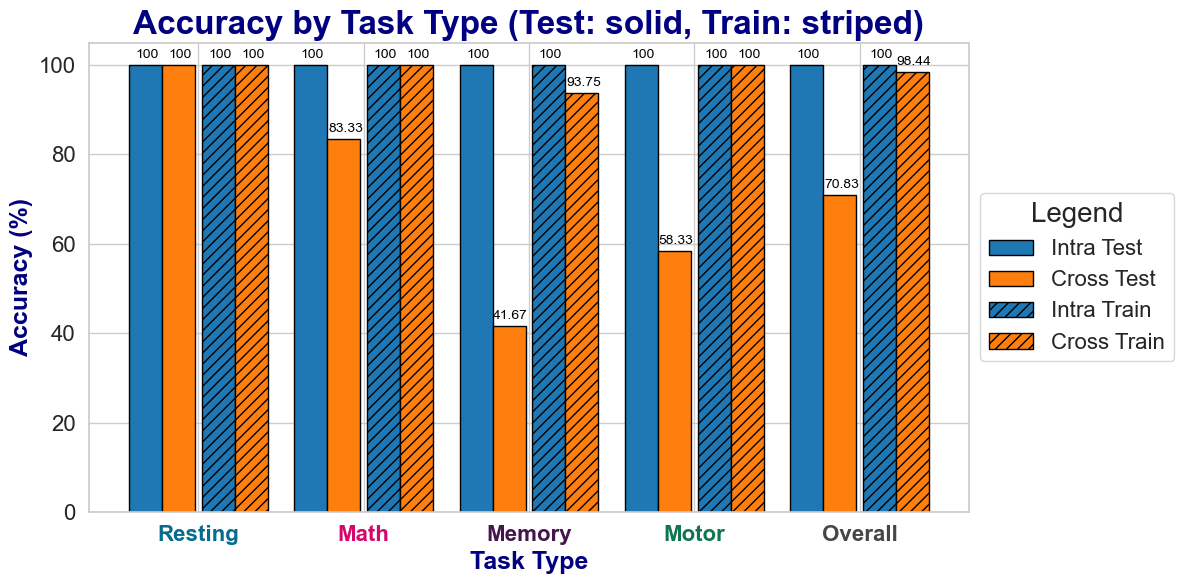

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

output_dir = "./Output"

# File paths
intra_path = rf"{output_dir}\Intra\test_metrics_MultiviewAttention_intra_20250601_225149.csv"
cross_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250601_122704.csv"
train_intra_path = rf"{output_dir}\Intra\train_metrics_MultiviewAttention_intra_20250609_124207.csv"
train_cross_path = rf"{output_dir}\Cross\train_metrics_MultiviewAttention_cross_20250609_123235.csv"

# Load files
df_intra = pd.read_csv(intra_path)
df_cross = pd.read_csv(cross_path)
df_train_intra = pd.read_csv(train_intra_path)
df_train_cross = pd.read_csv(train_cross_path)

# Task mapping
task_map = {0: "Resting", 1: "Math", 2: "Memory", 3: "Motor"}

# Intra test
df_intra["task"] = df_intra["y_true"].map(task_map)
intra_accuracies = {task: (df_intra[df_intra["task"] == task]["y_true"] == df_intra[df_intra["task"] == task]["y_pred"]).mean()
                    for task in task_map.values()}
intra_accuracies["Overall"] = (df_intra["y_true"] == df_intra["y_pred"]).mean()

# Cross test
df_cross["task"] = df_cross["y_true"].map(task_map)
cross_accuracies = {task: (df_cross[df_cross["task"] == task]["y_true"] == df_cross[df_cross["task"] == task]["y_pred"]).mean()
                    for task in task_map.values()}
cross_accuracies["Overall"] = (df_cross["y_true"] == df_cross["y_pred"]).mean()

# Train values
train_intra_vals = {
    "Resting": df_train_intra["resting_accuracy"].iloc[0],
    "Math": df_train_intra["math_accuracy"].iloc[0],
    "Memory": df_train_intra["memory_accuracy"].iloc[0],
    "Motor": df_train_intra["motor_accuracy"].iloc[0],
    "Overall": df_train_intra["overall_accuracy"].iloc[0]
}
train_cross_vals = {
    "Resting": df_train_cross["resting_accuracy"].iloc[0],
    "Math": df_train_cross["math_accuracy"].iloc[0],
    "Memory": df_train_cross["memory_accuracy"].iloc[0],
    "Motor": df_train_cross["motor_accuracy"].iloc[0],
    "Overall": df_train_cross["overall_accuracy"].iloc[0]
}

# Build DataFrame for plotting
def build_rows(source_dict, set_name, pattern):
    return [{"Task Type": task, "Accuracy": val * 100, "Set": set_name, "Pattern": pattern}
            for task, val in source_dict.items()]

df = pd.DataFrame(
    build_rows(intra_accuracies, "Intra Test", "solid") +
    build_rows(cross_accuracies, "Cross Test", "solid") +
    build_rows(train_intra_vals, "Intra Train", "striped") +
    build_rows(train_cross_vals, "Cross Train", "striped")
)

# Set style
sns.set(style="whitegrid")

# Create the barplot
fig, ax = plt.subplots(figsize=(12, 6))

task_order = ["Resting", "Math", "Memory", "Motor", "Overall"]
task_title_colors = ["#056c8e", "#d3086e", "#46154E", "#0e774f", "#494545"]
task_color_map = dict(zip(task_order, task_title_colors))

task_types = df['Task Type'].unique()
positions = list(range(len(task_types)))
bar_width = 0.2
offsets = [-1.5, -0.5, 0.5, 1.5]
set_order = ['Intra Test', 'Cross Test', 'Intra Train', 'Cross Train']
offsets = [-1.6, -0.6, 0.6, 1.6]  # Adjusted offsets for more spacing


palette = {
    'Intra Test': '#1f77b4',   # Blue
    'Cross Test': '#ff7f0e',   # Orange
    'Intra Train': '#1f77b4',
    'Cross Train': '#ff7f0e'
}
hatch_dict = {'solid': '', 'striped': '///'}


for i, s in enumerate(set_order):
    subset = df[df['Set'] == s]
    xs = [p + offsets[i]*bar_width for p in positions]
    bars = ax.bar(xs,
                  subset['Accuracy'],
                  width=bar_width,
                  label=s,
                  color=palette[s],
                  hatch=hatch_dict[subset['Pattern'].values[0]],
                  edgecolor='black')

    for bar in bars:
        height = bar.get_height()
        label = f"{int(height)}" if np.isclose(height, 100) else f"{height:.2f}"
        ax.annotate(f'{label}',
                    xy=(bar.get_x() + bar.get_width() / 2 + 0.01, height),  # Adjusted x-coordinate
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, rotation=0, color='black')

# Final touches
ax.set_xticks(positions)
ax.set_xticklabels(task_types, fontsize=16, fontweight='bold')

# Increase y-axis tick font size
ax.tick_params(axis='y', labelsize=16)  # Set labelsize to desired font size

# Set tick label colors based on task
for tick_label, color in zip(ax.get_xticklabels(), task_title_colors):
    tick_label.set_color(color)
ax.set_ylabel('Accuracy (%)', fontsize=18, fontweight='bold', color='navy')
ax.set_xlabel('Task Type', fontsize=18, fontweight='bold', color='navy')
ax.set_title('Accuracy by Task Type (Test: solid, Train: striped)', fontsize=24, fontweight='bold', color='navy')
# ax.legend(title='Legend', fontsize=10, title_fontsize=11)
ax.legend(title='Legend', fontsize=16, title_fontsize=20, loc='center left', bbox_to_anchor=(1.0, 0.5))

plt.tight_layout()
# plt.tight_layout(rect=[0, 0, 0.85, 1]) # Example: adjust right boundary to make space
plt.savefig(rf"{output_dir}\Cross_Vs_Intra_with_train.png", dpi=100, bbox_inches='tight')
plt.show()


In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_metric_heatmaps_by_parameters(df, parameters, metric="accuracy", cmap="Blues"):
    ncols = 4
    nrows = (len(parameters) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 6 * nrows), facecolor='white')
    axes = axes.flatten()

    # Set main figure title
    fig.suptitle("Accuracy by Hyperparameters", fontsize=28, weight='bold', color='darkblue', y=1)

    for i, param in enumerate(parameters):
        ax = axes[i]
        ax.set_facecolor('white')

        if df[param].dtype == "float64":
            df[param] = df[param].round(4)

        task_cols = [col for col in df.columns if col.startswith("val_") and col.endswith(f"_{metric}")]
        if not task_cols:
            ax.set_title(f"No test {metric} columns found", color='red', fontsize=18)
            ax.axis("off")
            continue

        grouped = df[[param] + task_cols].groupby(param).mean()
        renamed = grouped.rename(columns=lambda col: col.split("_")[1])
        transposed = renamed.transpose()

        ax = sns.heatmap(
            transposed,
            ax=ax,
            cmap=cmap,
            cbar=True,
            linewidths=0.8,
            linecolor="white",
            cbar_kws={"label": f"{metric.capitalize()} (%)"}
        )
        cbar = ax.collections[0].colorbar
        cbar.ax.yaxis.label.set_size(22)
        cbar.ax.tick_params(labelsize=18, colors='black')
        cbar.outline.set_edgecolor('black')

        # Only parameter name in subplot title
        ax.set_title(param.replace('_', ' ').title(), fontsize=20, weight='bold', color='indigo')
        ax.set_xlabel("Value", fontsize=22, color='navy', weight='bold',)
        ax.set_ylabel("Task Type", fontsize=22, color='navy', weight='bold',)
        ax.tick_params(axis='both', labelsize=20, colors='black')

        # Rotate x-tick labels more and reduce font size for clarity
        ax.set_xticklabels(ax.get_xticklabels(), rotation=75, ha='right', fontsize=16, color='black')
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20, color='black')

        # Optionally, show only every Nth label if too many
        if len(ax.get_xticklabels()) > 20:
            for idx, label in enumerate(ax.get_xticklabels()):
                if idx % 2 != 0:
                    label.set_visible(False)

    for j in range(len(parameters), len(axes)):
        fig.delaxes(axes[j])

    plt.subplots_adjust(wspace=0.3, hspace=0.3, top=0.90)
    plt.tight_layout()
    plt.savefig(rf"{output_dir}\Hyperparameter_Heatmaps.png", dpi=100, bbox_inches='tight')
    plt.show()

Index(['trial_id', 'epoch', 'train_overall_accuracy', 'train_overall_F1',
       'train_overall_recall', 'train_overall_precision',
       'train_resting_accuracy', 'train_resting_F1', 'train_resting_recall',
       'train_resting_precision', 'train_math_accuracy', 'train_math_F1',
       'train_math_recall', 'train_math_precision', 'train_memory_accuracy',
       'train_memory_F1', 'train_memory_recall', 'train_memory_precision',
       'train_motor_accuracy', 'train_motor_F1', 'train_motor_recall',
       'train_motor_precision', 'val_overall_accuracy', 'val_overall_F1',
       'val_overall_recall', 'val_overall_precision', 'val_resting_accuracy',
       'val_resting_F1', 'val_resting_recall', 'val_resting_precision',
       'val_math_accuracy', 'val_math_F1', 'val_math_recall',
       'val_math_precision', 'val_memory_accuracy', 'val_memory_F1',
       'val_memory_recall', 'val_memory_precision', 'val_motor_accuracy',
       'val_motor_F1', 'val_motor_recall', 'val_motor_precision',

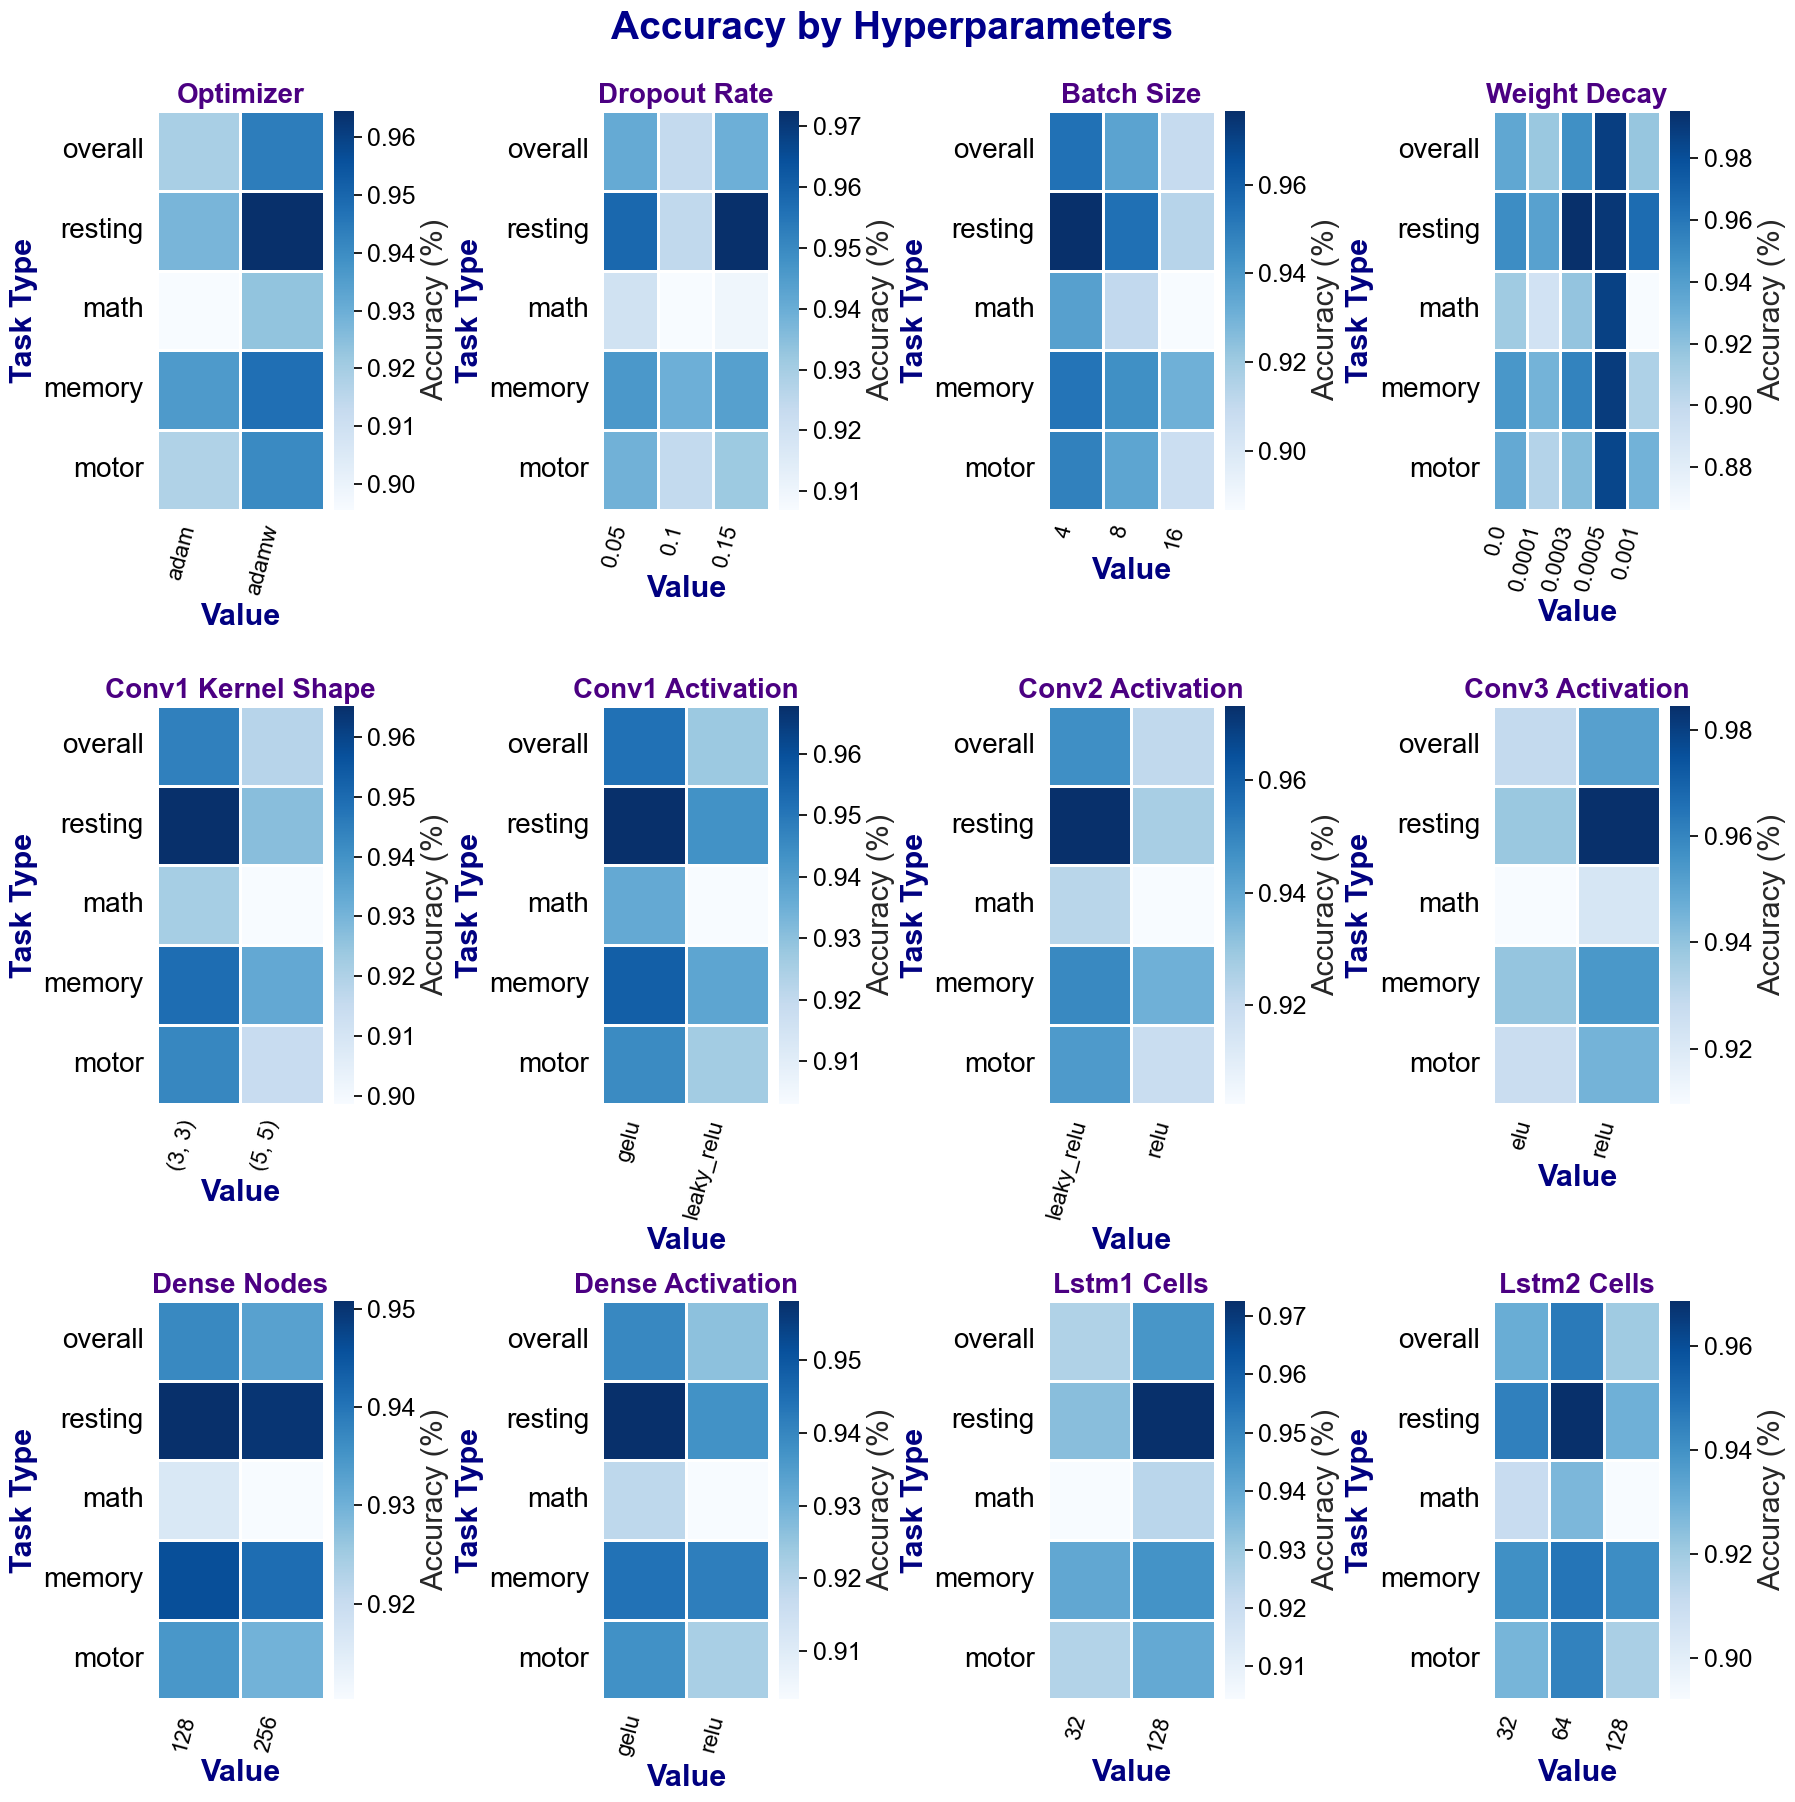

In [33]:
# Usage
all_metrics_df = pd.read_csv(rf"{output_dir}\Cross\best_model_MultiviewAttention_cross_20250531_195521.csv")#best_model_MultiviewAttention_cross_20250601_122704.csv")

print(all_metrics_df.columns)

# parameters_to_plot = ["learning_rate", "dropout_rate", "batch_size"]

parameters_to_plot = [
    'optimizer',
    'dropout_rate',
    'batch_size',
    'weight_decay',
    'conv1_kernel_shape',
    'conv1_activation',
    'conv2_activation',
    'conv3_activation',
    'dense_nodes',
    'dense_activation',
    'lstm1_cells',
    'lstm2_cells',
#     'dense3_nodes',
#     'dense3_activation'
]
plot_metric_heatmaps_by_parameters(all_metrics_df, parameters_to_plot, metric="accuracy")

In [34]:
cross1_train_per_patient_path = rf"{output_dir}\Cross\train_per_patient_task_accuracy_MultiviewAttention_cross_20250609_123235.csv"
cross1_train_per_patient = pd.read_csv(cross1_train_per_patient_path)
print("Cross1 Train Per Patient DataFrame:")
display(HTML(cross1_train_per_patient.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))



cross2_train_per_patient_path = rf"{output_dir}\Cross\train_per_patient_task_accuracy_MultiviewAttention_cross_20250609_151119.csv"
cross2_train_per_patient = pd.read_csv(cross2_train_per_patient_path)
print("Cross2 Train Per Patient DataFrame:")
display(HTML(cross2_train_per_patient.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

Cross1 Train Per Patient DataFrame:


,patient_id,0,1,2,3
0,113922,1,1,1.000,1
1,164636,1,1,0.875,1


Cross2 Train Per Patient DataFrame:


,patient_id,0,1,2,3
0,113922,1.0,1.0,1.0,1.0
1,164636,1.0,1.0,1.0,1.0


In [35]:
TASKS = ["resting", "math", "memory", "motor"]

# File paths
cross1_test_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250601_122704.csv"
cross2_test_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250529_213144.csv"
cross1_train_path = rf"{output_dir}\Cross\train_per_patient_task_accuracy_MultiviewAttention_cross_20250609_123235.csv"
cross2_train_path = rf"{output_dir}\Cross\train_per_patient_task_accuracy_MultiviewAttention_cross_20250609_151119.csv"

# Load files
df_cross1_test = pd.read_csv(cross1_test_path)
df_cross2_test = pd.read_csv(cross2_test_path)
df_cross1_train = pd.read_csv(cross1_train_path)
df_cross2_train = pd.read_csv(cross2_train_path)

# Unite train and test data for each cross
df_cross1_test["Set"] = "Test"
df_cross2_test["Set"] = "Test"

df_cross1_train["Set"] = "Train"
df_cross2_train["Set"] = "Train"

print("Cross1 Test DataFrame:")
display(HTML(df_cross1_test.head(100).to_html(max_rows=100, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

print("Cross2 Test DataFrame:")
display(HTML(df_cross2_test.head(100).to_html(max_rows=100, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

Cross1 Test DataFrame:


,y_true,y_pred,patient_id,Set
0,0,0,162935,Test
1,0,0,162935,Test
2,0,0,162935,Test
3,0,0,162935,Test
4,1,1,162935,Test
5,1,1,162935,Test
6,1,1,162935,Test
7,1,1,162935,Test
8,2,1,162935,Test
9,2,2,162935,Test


Cross2 Test DataFrame:


,y_true,y_pred,patient_id,Set
0,0,0,162935,Test
1,0,0,162935,Test
2,0,0,162935,Test
3,0,0,162935,Test
4,1,1,162935,Test
5,1,1,162935,Test
6,1,1,162935,Test
7,1,1,162935,Test
8,2,2,162935,Test
9,2,2,162935,Test


C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1705717699.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  overall_acc_per_task_test = test_df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1705717699.py:41: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_patient_acc_test = test_df.groupby(['patient_id', 'y_true']).apply(lamb

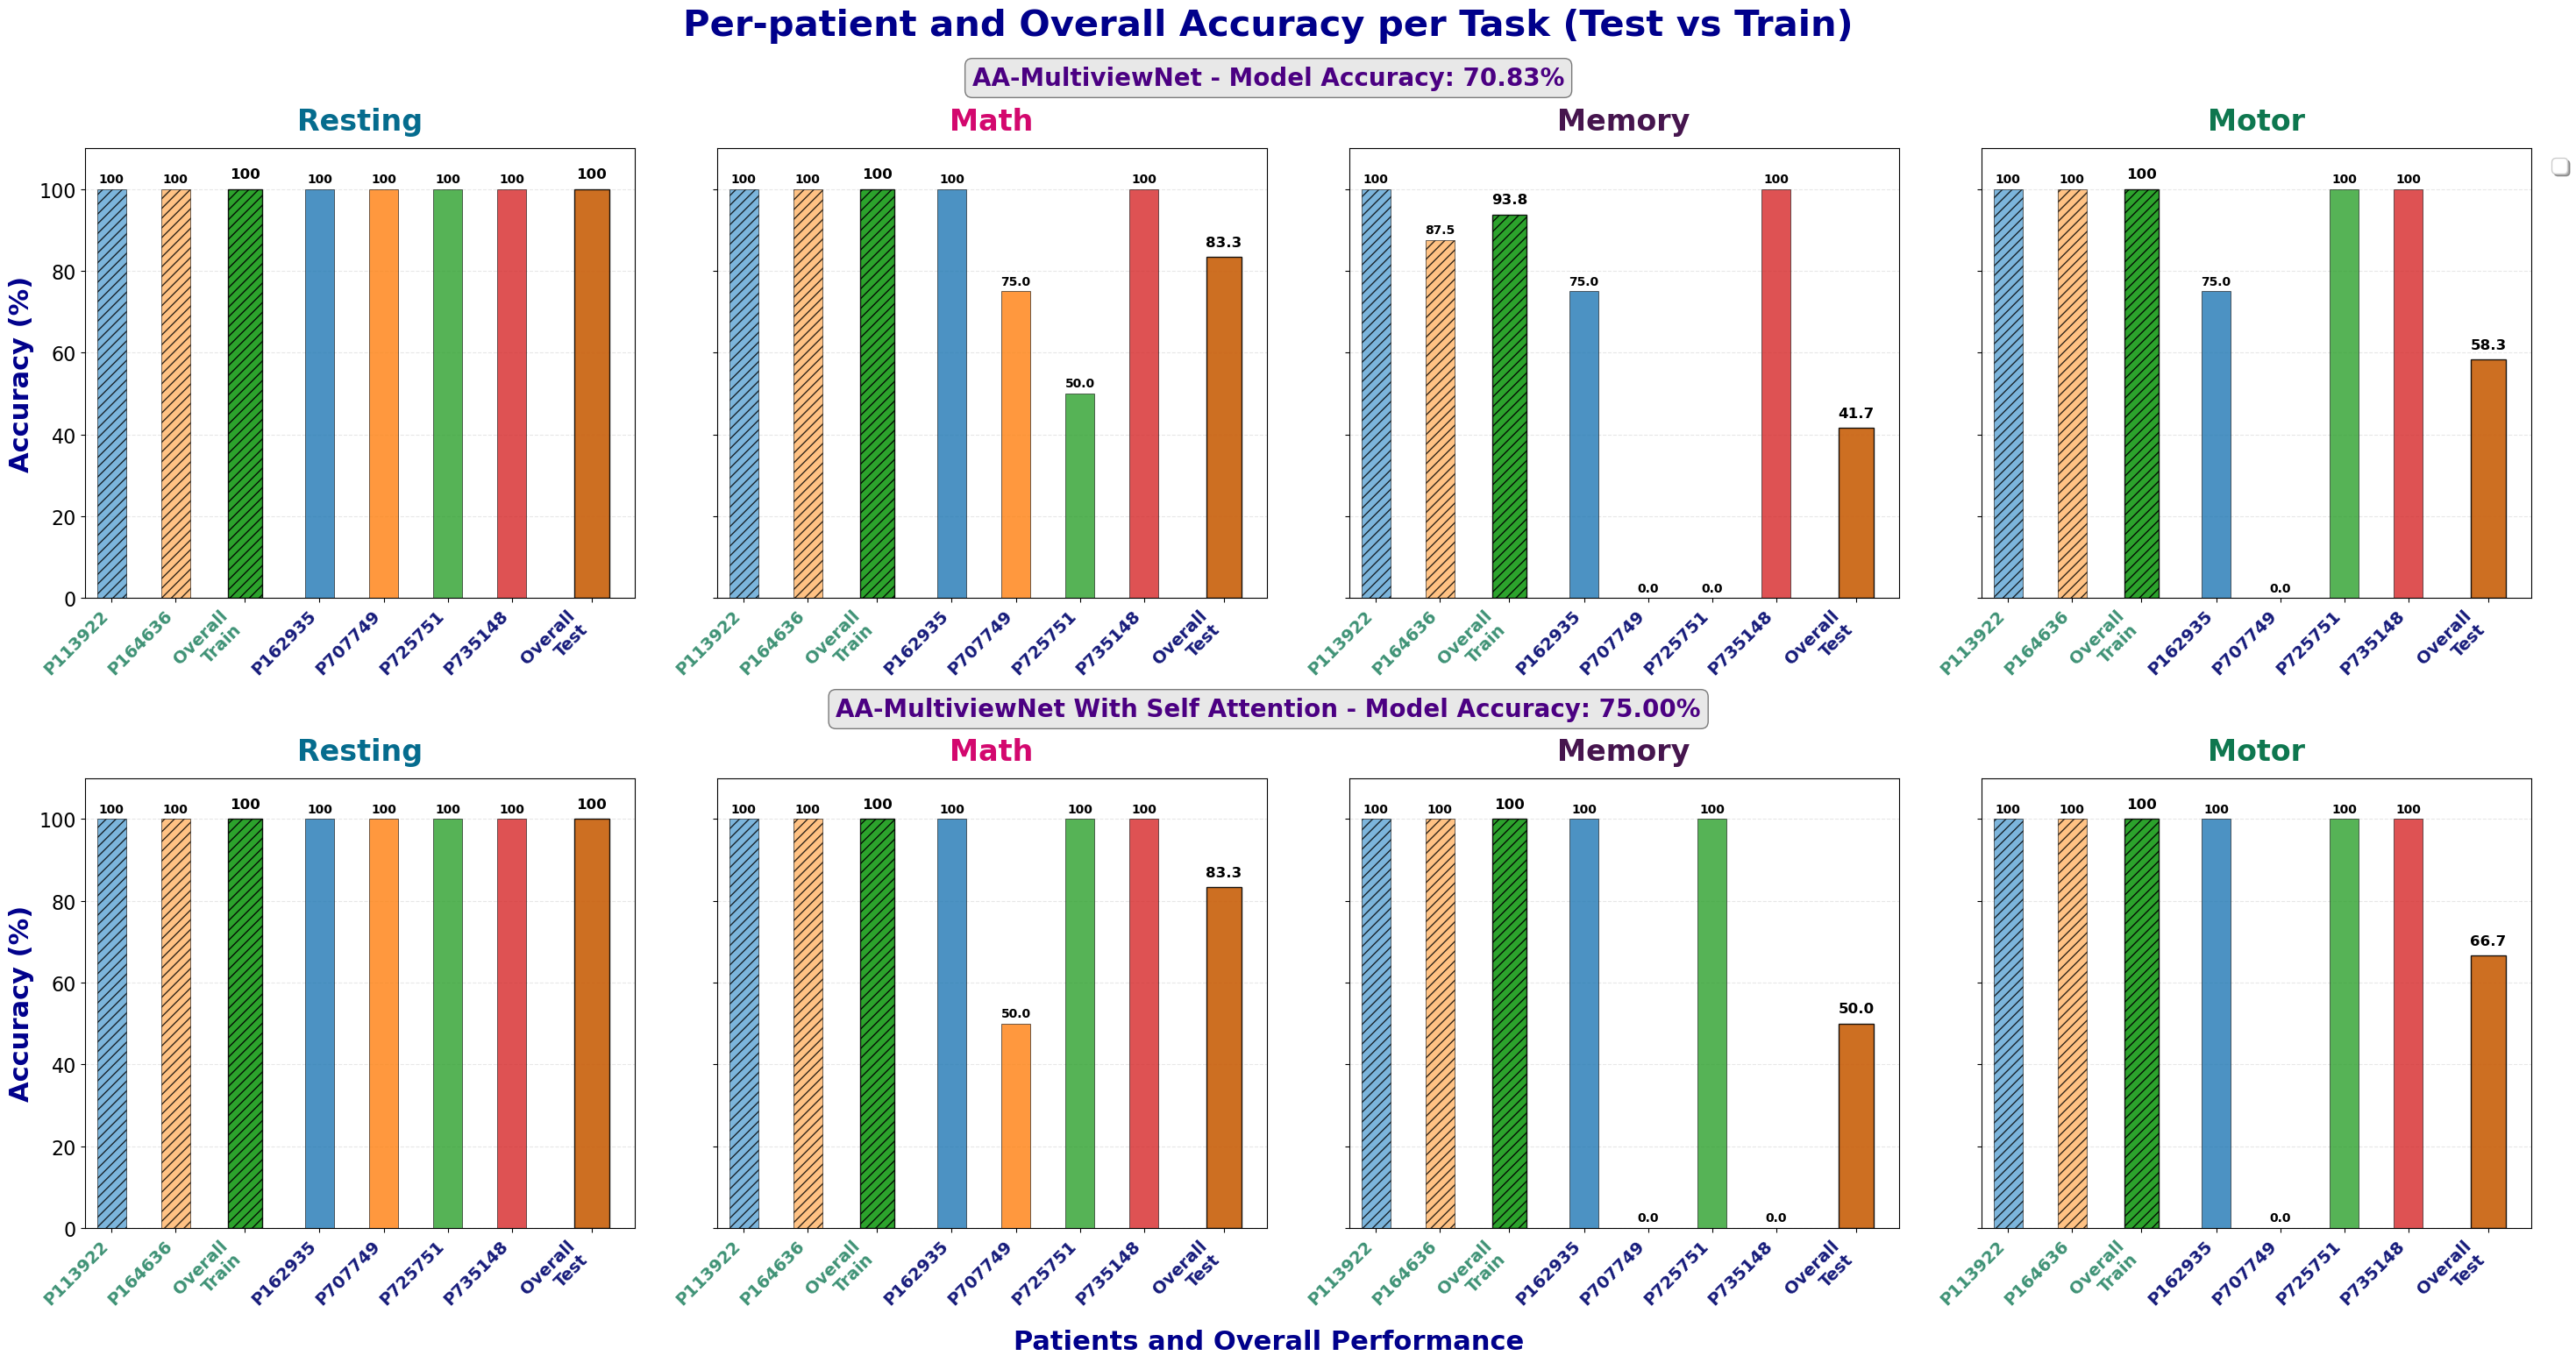

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

TASKS = ["Resting", "Math", "Memory", "Motor"]

def plot_per_patient_accuracy_bars_dual_improved(
    test_df1, test_df2, train_df1, train_df2,
    task_names=["resting", "math", "memory", "motor"],
    style="default",
    subtitles=["Dataset 1", "Dataset 2"]
):
    """
    Improved version with better alignment and visibility.
    Plots per-patient and overall accuracy per task for two datasets as grouped bar plots.
    """
    plt.style.use(style)
    dfs = [(test_df1, train_df1), (test_df2, train_df2)]
    n_tasks = len(task_names)
    fig, axs = plt.subplots(2, n_tasks, figsize=(9 * n_tasks, 16), sharey=True, 
                           gridspec_kw={'hspace': 0.4, 'wspace': 0.15})

    # Enhanced color schemes with better contrast
    test_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    train_colors = ['#5ba3d4', '#ffb366', '#66c266', '#e85858', '#b388d6', '#a67a7a', '#f7c6e2', '#a6a6a6']
    overall_test_color = "#C85F0A"  # Dark red
    overall_train_color = "#159915"  # Dark green
    task_title_colors = ["#056c8e", "#d3086e", "#46154E", "#0e774f"]

    # Store overall accuracies for subtitles
    overall_accuracies = []
    
    # Bar width and spacing
    bar_width = 0.54
    spacing = 0.1

    for row, (test_df, train_df) in enumerate(dfs):
        # Compute accuracies (same as before)
        if not test_df.empty:
            overall_acc_per_task_test = test_df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
            per_patient_acc_test = test_df.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == x['y_pred']).mean()).unstack(0)
            overall_acc_test = (test_df['y_true'] == test_df['y_pred']).mean()
        else:
            overall_acc_per_task_test = pd.Series(dtype=float)
            per_patient_acc_test = pd.DataFrame()
            overall_acc_test = 0

        if not train_df.empty:
            overall_acc_per_task_train = train_df.drop(columns=['Set']).mean(axis=0)
            per_patient_acc_train = train_df.set_index("patient_id")
            overall_acc_train = overall_acc_per_task_train.mean()
        else:
            overall_acc_per_task_train = pd.Series(dtype=float)
            per_patient_acc_train = pd.DataFrame()
            overall_acc_train = 0

        overall_accuracies.append(overall_acc_test)

        # Get all unique patients and sort them
        train_patients = sorted(per_patient_acc_train.index.tolist()) if not per_patient_acc_train.empty else []
        test_patients = sorted(per_patient_acc_test.columns.tolist()) if not per_patient_acc_test.empty else []
        
        # Create x positions for train and test bars separately
        x_train_patients = np.arange(len(train_patients)) * 1.2  # Train patients on the left
        x_test_patients = np.arange(len(test_patients)) * 1.2 + len(train_patients) * 1.2 + 1.5  # Test patients on the right
        x_overall_train = len(train_patients) * 1.2 + 0.1  # Overall train bar on the left
        # x_overall_train = len(train_patients) * 1.2 / 2 - bar_width / 2  # Centered above train patient bars
        x_overall_test = x_test_patients[-1] + 1.5  # Overall test bar on the right

        for t_idx, t in enumerate(range(len(task_names))):
            ax = axs[row, t_idx]
            
            # Calculate overall_train and overall_test for the current task
            overall_train = overall_acc_per_task_train.loc[str(t)] * 100 if str(t) in overall_acc_per_task_train.index else 0
            overall_test = overall_acc_per_task_test.loc[t] * 100 if t in overall_acc_per_task_test.index else 0
            
            # Plot per-patient bars
            for i, patient in enumerate(train_patients):
                # Train bars
                acc_train = per_patient_acc_train.loc[patient, str(t)] * 100 if patient in per_patient_acc_train.index and str(t) in per_patient_acc_train.columns else 0
                train_bar = ax.bar(x_train_patients[i], acc_train, bar_width,
                                   color=train_colors[i % len(train_colors)],
                                   alpha=0.8, edgecolor='black', linewidth=0.5, hatch='///',
                                   label='Train' if i == 0 and row == 0 and t_idx == 0 else "")
                if acc_train >= 0:
                    label_train = f"{int(acc_train)}" if np.isclose(acc_train, 100) else f"{acc_train:.1f}"
                    ax.text(x_train_patients[i], acc_train + 1, label_train,
                            ha='center', va='bottom', fontsize=10, fontweight='bold')

            for i, patient in enumerate(test_patients):
                # Test bars
                acc_test = per_patient_acc_test.loc[t, patient] * 100 if patient in per_patient_acc_test.columns and t in per_patient_acc_test.index else 0
                test_bar = ax.bar(x_test_patients[i], acc_test, bar_width,
                                  color=test_colors[i % len(test_colors)],
                                  alpha=0.8, edgecolor='black', linewidth=0.5,
                                  label='Test' if i == 0 and row == 0 and t_idx == 0 else "")
                if acc_test >= 0:
                    label_test = f"{int(acc_test)}" if np.isclose(acc_test, 100) else f"{acc_test:.1f}"
                    ax.text(x_test_patients[i], acc_test + 1, label_test,
                            ha='center', va='bottom', fontsize=10, fontweight='bold')

            # Plot overall bars
            ax.bar(x_overall_train, overall_train, bar_width * 1.2,
                color=overall_train_color, alpha=0.9, edgecolor='black', linewidth=1, hatch='///',
                label='Overall Train' if row == 0 and t_idx == 0 else "")
            if overall_train >= 0:
                label_train = f"{int(overall_train)}" if np.isclose(overall_train, 100) else f"{overall_train:.1f}"
                ax.text(x_overall_train, overall_train + 2, label_train,
                        ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

            ax.bar(x_overall_test, overall_test, bar_width * 1.2,
                   color=overall_test_color, alpha=0.9, edgecolor='black', linewidth=1,
                   label='Overall Test' if row == 0 and t_idx == 0 else "")
            if overall_test >= 0:
                label_test = f"{int(overall_test)}" if np.isclose(overall_test, 100) else f"{overall_test:.1f}"
                ax.text(x_overall_test, overall_test + 2, label_test,
                        ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

            # Set x-ticks and labels
            all_x_positions = list(x_train_patients) + [x_overall_train] + list(x_test_patients) + [x_overall_test]
            all_labels = [f"P{p}" for p in train_patients] + ["Overall\nTrain"] + [f"P{p}" for p in test_patients] + ["Overall\nTest"]

            ax.set_xticks(all_x_positions)
            ax.set_xticklabels(all_labels, fontsize=14, fontweight='bold', rotation=45, ha='right')

            # Color x-ticks for train and test patients differently
            for i, label in enumerate(ax.get_xticklabels()):
                label.set_fontweight('bold')
                if i < len(train_patients) + 1:  # Train patients and overall train
                    label.set_color("#3E9275")  # Dark green for train
                else:  # Test patients and overall test
                    label.set_color("#151A7A")  # Dark red for test

            # Set x-axis limits to accommodate the wider spread
            ax.set_xlim(-0.5, x_overall_test + 0.8)
            
            # Formatting
            if row == 0 or row == 1:
                ax.set_title(task_names[t_idx], fontsize=24, fontweight='bold', 
                           color=task_title_colors[t_idx % len(task_title_colors)], pad=15)
            
            ax.set_ylim(0, 110)
            ax.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)
            ax.tick_params(axis='y', labelsize=16)
            ax.set_axisbelow(True)
            
            if t_idx == 0:
                ax.set_ylabel('Accuracy (%)', fontsize=22, fontweight='bold', color='darkblue')
            
            # Add legend only to the last subplot
            if row == 0 and t_idx == n_tasks - 1:
                ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.02, 1.0),
                         frameon=True, fancybox=True, shadow=True)

    # Add subtitles with improved positioning
    subtitle_y_positions = [0.93, 0.48]
    
    for row, subtitle in enumerate(subtitles):
        fig.text(0.5, subtitle_y_positions[row],
                f"{subtitle} - Model Accuracy: {overall_accuracies[row]*100:.2f}%",
                ha='center', va='center', fontsize=20, fontweight='bold', 
                color='indigo', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.5))

    # Enhanced main labels and title
    fig.supxlabel('Patients and Overall Performance', fontsize=22, fontweight='bold', 
                  color='darkblue', y=0.02)
    fig.suptitle('Per-patient and Overall Accuracy per Task (Test vs Train)', 
                fontsize=30, fontweight='bold', color='darkblue', y=0.98)
    
    # Adjust layout
    plt.tight_layout(rect=[0, 0.05, 0.95, 0.95])
    
    # Save with higher DPI for better quality
    plt.savefig(f"{output_dir}/per_patient_accuracy_bars_dual_improved.png", 
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

# Usage remains the same:
plot_per_patient_accuracy_bars_dual_improved(
    df_cross1_test, df_cross2_test, df_cross1_train, df_cross2_train, 
    task_names=TASKS, 
    subtitles=["AA-MultiviewNet", "AA-MultiviewNet With Self Attention"]
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

TASKS = ["resting", "math", "memory", "motor"]

def plot_per_patient_accuracy_bars_dual_improved(
    test_df1, test_df2, train_df1, train_df2,
    task_names=["resting", "math", "memory", "motor"],
    style="default",
    subtitles=["Dataset 1", "Dataset 2"]
):
    """
    Improved version with better alignment and visibility.
    Plots per-patient and overall accuracy per task for two datasets as grouped bar plots.
    """
    plt.style.use(style)
    dfs = [(test_df1, train_df1), (test_df2, train_df2)]
    n_tasks = len(task_names)
    fig, axs = plt.subplots(2, n_tasks, figsize=(9 * n_tasks, 16), sharey=True, 
                           gridspec_kw={'hspace': 0.4, 'wspace': 0.15})

    # Enhanced color schemes with better contrast
    test_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    train_colors = ['#5ba3d4', '#ffb366', '#66c266', '#e85858', '#b388d6', '#a67a7a', '#f7c6e2', '#a6a6a6']
    overall_test_color = "#C85F0A"  # Dark red
    overall_train_color = "#006400"  # Dark green
    task_title_colors = ["#056c8e", "#d3086e", "#46154E", "#0e774f"]

    # Store overall accuracies for subtitles
    overall_accuracies = []
    
    # Bar width and spacing
    bar_width = 0.54
    spacing = 0.1

    for row, (test_df, train_df) in enumerate(dfs):
        # Compute accuracies (same as before)
        if not test_df.empty:
            overall_acc_per_task_test = test_df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
            per_patient_acc_test = test_df.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == x['y_pred']).mean()).unstack(0)
            overall_acc_test = (test_df['y_true'] == test_df['y_pred']).mean()
        else:
            overall_acc_per_task_test = pd.Series(dtype=float)
            per_patient_acc_test = pd.DataFrame()
            overall_acc_test = 0

        if not train_df.empty:
            overall_acc_per_task_train = train_df.mean(axis=0)
            per_patient_acc_train = train_df.set_index("patient_id")
            overall_acc_train = overall_acc_per_task_train.mean()
        else:
            overall_acc_per_task_train = pd.Series(dtype=float)
            per_patient_acc_train = pd.DataFrame()
            overall_acc_train = 0

        overall_accuracies.append(overall_acc_test)

        # Get all unique patients and sort them
        train_patients = sorted(per_patient_acc_train.index.tolist()) if not per_patient_acc_train.empty else []
        test_patients = sorted(per_patient_acc_test.columns.tolist()) if not per_patient_acc_test.empty else []
        all_patients = sorted(set(train_patients + test_patients))
        
        n_patients = len(all_patients)
        
        for t_idx, t in enumerate(range(len(task_names))):
            ax = axs[row, t_idx]
            
            # Create x positions for bars with better spacing
            x_patients = np.arange(n_patients) * 1.2  # Add spacing between patients
            x_overall_test = x_patients[-1] + 2.0 if n_patients > 0 else 2.0  # Reasonable gap
            x_overall_train = x_overall_test + 1.5  # Close to test overall
            
            # Plot per-patient bars
            test_bars = []
            train_bars = []
            
            for i, patient in enumerate(all_patients):
                x_pos = x_patients[i]  # Use the spaced x positions
                
                # Test bars
                if patient in per_patient_acc_test.columns and t in per_patient_acc_test.index:
                    acc_test = per_patient_acc_test.loc[t, patient] * 100
                else:
                    acc_test = 0
                
                # Train bars  
                if patient in per_patient_acc_train.index and str(t) in per_patient_acc_train.columns:
                    acc_train = per_patient_acc_train.loc[patient, str(t)] * 100
                else:
                    acc_train = 0
                
                # Plot test bar
                test_bar = ax.bar(x_pos - bar_width/2, acc_test, bar_width, 
                                color=test_colors[i % len(test_colors)], 
                                alpha=0.8, edgecolor='black', linewidth=0.5,
                                label='Test' if i == 0 and row == 0 and t_idx == 0 else "")
                test_bars.extend(test_bar)
                
                # Plot train bar
                train_bar = ax.bar(x_pos + bar_width/2, acc_train, bar_width,
                                 color=train_colors[i % len(train_colors)], 
                                 alpha=0.8, edgecolor='black', linewidth=0.5,
                                 hatch='///', 
                                 label='Train' if i == 0 and row == 0 and t_idx == 0 else "")
                train_bars.extend(train_bar)
                
                # Add value labels on bars
                if acc_test > 0:
                    if np.isclose(acc_test, 100) or acc_test == 0:
                        label_test = f"{int(acc_test)}"
                    else:
                        label_test = f"{acc_test:.1f}"

                    ax.text(x_pos - bar_width/2, acc_test + 1, label_test, 
                           ha='center', va='bottom', fontsize=10, fontweight='bold')
                
                if acc_train > 0:
                    label_train = f"{int(acc_train)}" if np.isclose(acc_train, 100) else f"{acc_train:.1f}"
                    ax.text(x_pos + bar_width/2, acc_train + 1, label_train, 
                           ha='center', va='bottom', fontsize=10, fontweight='bold')

            # Plot overall bars
            overall_test = overall_acc_per_task_test.loc[t] * 100 if t in overall_acc_per_task_test.index else 0
            overall_train = overall_acc_per_task_train.loc[str(t)] * 100 if str(t) in overall_acc_per_task_train.index else 0
            
            # Overall test bar
            ax.bar(x_overall_test, overall_test, bar_width * 1.2,
                  color=overall_test_color, alpha=0.9, edgecolor='black', linewidth=1,
                  label='Overall Test' if row == 0 and t_idx == 0 else "")
            
            # Overall train bar
            ax.bar(x_overall_train, overall_train, bar_width * 1.2,
                  color=overall_train_color, alpha=0.9, edgecolor='black', linewidth=1,
                  hatch='///', 
                  label='Overall Train' if row == 0 and t_idx == 0 else "")
            
            # Add labels for overall bars
            if overall_test >= 0:  # Show label even for 0
                label_test = f"{int(overall_test)}" if np.isclose(overall_test, round(overall_test)) else f"{overall_test:.1f}"
                ax.text(x_overall_test, overall_test + 2, label_test, 
                       ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')
            
            if overall_train >= 0:  # Show label even for 0
                label_train = f"{int(overall_train)}" if np.isclose(overall_train, round(overall_train)) else f"{overall_train:.1f}"
                ax.text(x_overall_train, overall_train + 2, label_train, 
                       ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

            # Set x-ticks and labels
            all_x_positions = list(x_patients) + [x_overall_test, x_overall_train]
            all_labels = [f"P{p}" for p in all_patients] + ["Overall\nTest", "Overall\nTrain"]
            
            ax.set_xticks(all_x_positions)
            ax.set_xticklabels(all_labels, fontsize=14, fontweight='bold', rotation=45, ha='right')

            
            # Color x-ticks for train and test patients differently
            for i, label in enumerate(ax.get_xticklabels()):
                label.set_fontweight('bold')
                if i < len(train_patients) or ("Train" in label.get_text()):  # Train patients
                    label.set_color("#3E9275")  # Dark green for train
                    
                elif i < len(train_patients) + len(test_patients) or ("Test" in label.get_text()):  # Test patients
                    label.set_color("#151A7A")  # Dark red for test
                else:  # Overall bars
                    label.set_color("black")  # Default black for overall
                        
            # Set x-axis limits to accommodate the wider spread
            ax.set_xlim(-0.5, x_overall_train + 0.8)
            
            # Formatting
            if row == 0 or row == 1:
                ax.set_title(task_names[t_idx], fontsize=24, fontweight='bold', 
                           color=task_title_colors[t_idx % len(task_title_colors)], pad=15)
            
            ax.set_ylim(0, 110)
            ax.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)
            ax.tick_params(axis='y', labelsize=16)
            ax.set_axisbelow(True)
            
            if t_idx == 0:
                ax.set_ylabel('Accuracy (%)', fontsize=22, fontweight='bold', color='darkblue')
            
            # Add legend only to the last subplot
            if row == 0 and t_idx == n_tasks - 1:
                ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.02, 1.0),
                         frameon=True, fancybox=True, shadow=True)

    # Add subtitles with improved positioning
    subtitle_y_positions = [0.93, 0.48]
    
    for row, subtitle in enumerate(subtitles):
        fig.text(0.5, subtitle_y_positions[row],
                f"{subtitle} - Model Accuracy: {overall_accuracies[row]*100:.2f}%",
                ha='center', va='center', fontsize=20, fontweight='bold', 
                color='indigo', bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.5))

    # Enhanced main labels and title
    fig.supxlabel('Patients and Overall Performance', fontsize=22, fontweight='bold', 
                  color='darkblue', y=0.02)
    fig.suptitle('Per-patient and Overall Accuracy per Task (Test vs Train)', 
                fontsize=30, fontweight='bold', color='darkblue', y=0.98)
    
    # Adjust layout
    plt.tight_layout(rect=[0, 0.05, 0.95, 0.95])
    
    # Save with higher DPI for better quality
    plt.savefig(f"{output_dir}/per_patient_accuracy_bars_dual_improved.png", 
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

# Usage remains the same:
plot_per_patient_accuracy_bars_dual_improved(
    df_cross1_test, df_cross2_test, df_cross1_train, df_cross2_train, 
    task_names=TASKS, 
    subtitles=["AA-MultiviewNet", "AA-MultiviewNet With Self Attention"]
)

In [ ]:
import matplotlib.pyplot as plt

TASKS = ["resting", "math", "memory", "motor"]

# File paths
cross1_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250601_122704.csv"
cross2_path = rf"{output_dir}\Cross\test_metrics_MultiviewAttention_cross_20250529_213144.csv"

# Load files
df_cross1 = pd.read_csv(cross1_path)
df_cross2 = pd.read_csv(cross2_path)

def plot_per_patient_accuracy_bars_dual(
    df1, df2, 
    task_names=["resting", "math", "memory", "motor"], 
    style="default", 
    subtitles=["Dataset 1", "Dataset 2"]
):
    """
    Plots per-patient and overall accuracy per task for two datasets as grouped bar plots in two subplots.
    """
    plt.style.use(style)
    dfs = [df1, df2]
    n_tasks = len(task_names)
    fig, axs = plt.subplots(2, n_tasks, figsize=(5*n_tasks, 13), sharey=True, gridspec_kw={'hspace': 0.5})

    bar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
    overall_color = "#9515b1"
    # task_title_colors = ['#00bfff', '#ff69b4', "#bba10d", '#00fa9a']
    task_title_colors = ["#056c8e", "#d3086e", "#46154E", "#0e774f", "#494545"]

    # Store overall accuracies for subtitles
    overall_accuracies = []

    for row, df in enumerate(dfs):
        # Compute overall accuracy per task
        overall_acc_per_task = df.groupby('y_true').apply(lambda x: (x['y_true'] == x['y_pred']).mean())
        per_patient_acc = df.groupby(['patient_id', 'y_true']).apply(lambda x: (x['y_true'] == x['y_pred']).mean()).unstack(0)
        overall_acc = (df['y_true'] == df['y_pred']).mean()
        overall_accuracies.append(overall_acc)
        tasks = sorted(df['y_true'].unique())
        patients = per_patient_acc.columns.tolist()
        n_bars = len(patients) + 1  # patients + overall

        for t_idx, t in enumerate(tasks):
            ax = axs[row, t_idx]
            # Per-patient bars
            for i, patient in enumerate(patients):
                acc = per_patient_acc[patient].reindex(tasks, fill_value=0)[t] * 100
                if np.isclose(acc, 100) or acc == 0:
                    label = int(acc)
                else:
                    label = f"{acc:.2f}"
                ax.bar(i, acc, color=bar_colors[i % len(bar_colors)], width=0.7, label=f'Patient {patient}' if row == 0 and t_idx == 0 else "", zorder=3)
                ax.text(i, acc + 2, label, ha='center', va='bottom', fontsize=16, color='black', fontweight='bold')
            # Overall bar
            overall = overall_acc_per_task.reindex(tasks, fill_value=0)[t] * 100
            label = f"{int(overall)}" if np.isclose(overall, 100) else f"{overall:.2f}"
            ax.bar(len(patients), overall, color=overall_color, width=0.7, label='Overall' if row == 0 and t_idx == 0 else "", zorder=3, hatch='///')
            ax.text(len(patients), overall + 2, label, ha='center', va='bottom', fontsize=16, color='black', fontweight='bold')
            # Formatting
            if row == 0:
                ax.set_title(task_names[t], fontsize=28, fontweight='bold', color=task_title_colors[t_idx % len(task_title_colors)])
            ax.set_xticks(list(range(n_bars)))
            ax.set_xticklabels([f"P{p}" for p in patients] + ["Overall"], fontsize=16, fontweight='bold', rotation=40, ha='right')
            ax.set_ylim(0, 118)
            ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
            ax.tick_params(axis='y', labelsize=18)
            if t_idx == 0:
                ax.set_ylabel('Accuracy (%)', fontsize=28, fontweight='bold', color='darkblue')
            if row == 1 and t_idx == n_tasks-1:
                ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))

    # Adjust y positions for better spacing between main title and subtitles
    subtitle_y_positions = [0.95, 0.45]  # Top row, bottom row

    for row, subtitle in enumerate(subtitles):
        fig.text(
            0.5, 
            subtitle_y_positions[row],
            f"{subtitle} - Model Accuracy: {overall_accuracies[row]*100:.2f}%",
            ha='center', va='center',
            fontsize=24, fontweight='bold', color='indigo'
        )

    fig.supxlabel('Patients', fontsize=28, fontweight='bold', color='darkblue')
    fig.suptitle('Per-patient and Overall Accuracy per Task', fontsize=30, fontweight='bold', color='darkblue', y=1.02)
    plt.tight_layout(rect=[0, 0.01, 0.96, 1])
    plt.savefig(f"{output_dir}/per_patient_accuracy_bars_dual.png", dpi=100, bbox_inches='tight')
    plt.show()

# Example usage:
plot_per_patient_accuracy_bars_dual(df_cross1, df_cross2, task_names=TASKS, subtitles=["AA-MultiviewNet", "AA-MultiviewNet With Self Attention"])

Loading cross dataset...
Loading cached: Data\Normalized\z_score_local\cross_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test1_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test2_scaled.pt
Loading cached: Data\Normalized\z_score_local\cross_test3_scaled.pt
Data for dataset cross was loaded successfully
Train data shape: torch.Size([64, 248, 5089])
Test data shape: torch.Size([48, 248, 5089])
Train DataFrame shape: (64, 11)
Test DataFrame shape: (48, 11)
Unique task types in train_df after mapping: ['math' 'memory' 'motor' 'resting']
Unique task types in test_df after mapping: ['math' 'memory' 'motor' 'resting']
Task: resting, Train indices: 16, Test indices: 12
Task: math, Train indices: 16, Test indices: 12
Task: memory, Train indices: 16, Test indices: 12
Task: motor, Train indices: 16, Test indices: 12


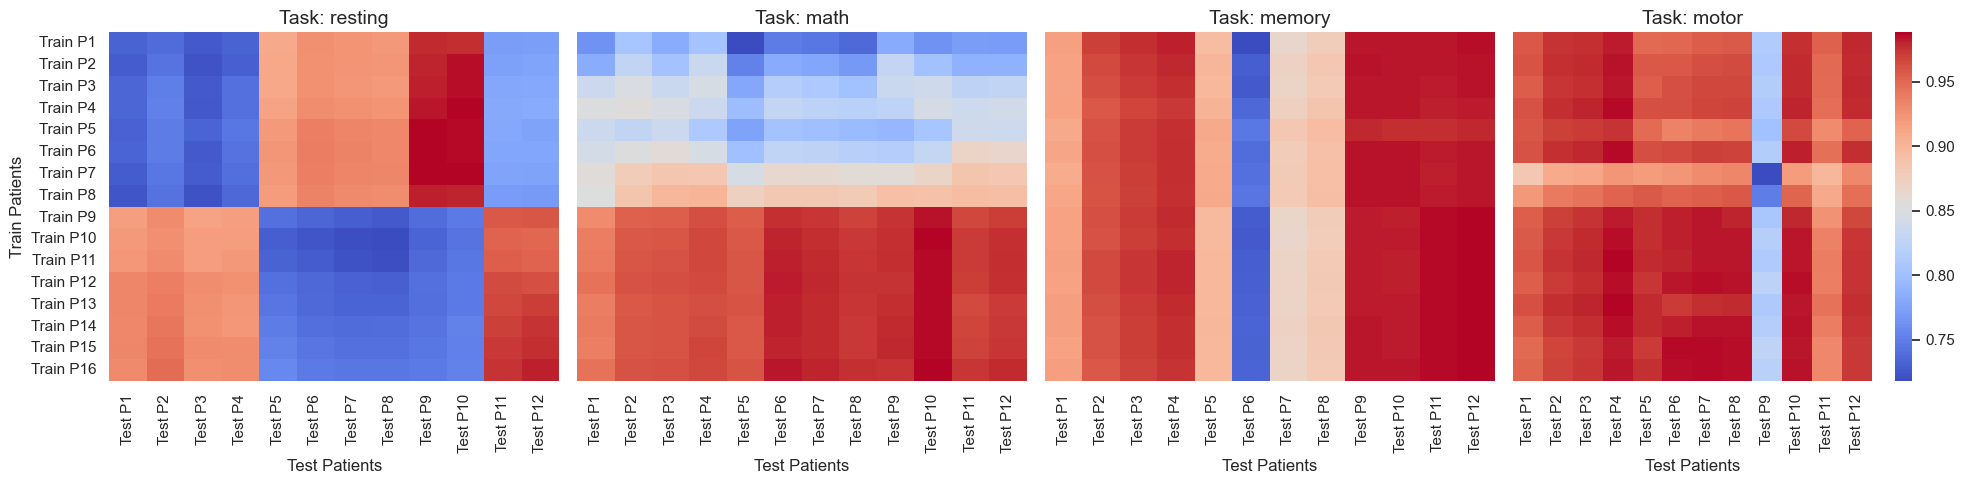

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import utils

# Define paths and parameters
data_dir = "./Data"
output_dir = "./Output"
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "cross"  # or "intra"
downsample = True
downsample_rate = 7 if downsample else 0

# Load datasets using the same approach as in notebook_cross.ipynb
train_data, train_df, test_data, test_df = utils.load_dataset(
    which_dataset=which_dataset,
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)

# Check if data is loaded correctly
print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)
print("Train DataFrame shape:", train_df.shape)
print("Test DataFrame shape:", test_df.shape)

# Example: Plot similarity heatmap between train and test patients for each task type
def plot_similarity_heatmaps(train_data, test_data, train_df, test_df, task_types, similarity_metric="cosine"):
    """
    Plots heatmaps of similarity between train and test patients for each task type.

    Args:
        train_data (torch.Tensor): Train data tensor of shape (N_train, C, T).
        test_data (torch.Tensor): Test data tensor of shape (N_test, C, T).
        train_df (pd.DataFrame): Train metadata DataFrame.
        test_df (pd.DataFrame): Test metadata DataFrame.
        task_types (list): List of task types (e.g., ["resting", "math", "memory", "motor"]).
        similarity_metric (str): Similarity metric to use ("cosine" or "correlation").
    """
    from sklearn.metrics.pairwise import cosine_similarity
    from scipy.stats import pearsonr

    # Convert PyTorch tensors to NumPy arrays
    train_data = train_data.numpy()
    test_data = test_data.numpy()

    fig, axes = plt.subplots(1, len(task_types), figsize=(5 * len(task_types), 5), sharey=True)
    if len(task_types) == 1:
        axes = [axes]  # Ensure axes is iterable for a single task type

    for i, task in enumerate(task_types):
        # Filter train and test data by task type
        train_indices = train_df[train_df["task_type"] == task].index
        test_indices = test_df[test_df["task_type"] == task].index

        # Debugging: Print indices and task
        print(f"Task: {task}, Train indices: {len(train_indices)}, Test indices: {len(test_indices)}")

        # Skip if no data is found for the task
        if len(train_indices) == 0 or len(test_indices) == 0:
            print(f"Skipping task '{task}' due to no data.")
            continue

        train_matrices = train_data[train_indices].reshape(len(train_indices), -1)
        test_matrices = test_data[test_indices].reshape(len(test_indices), -1)

        # Compute similarity matrix
        similarity_matrix = np.zeros((len(train_matrices), len(test_matrices)))
        for t_idx, train_matrix in enumerate(train_matrices):
            for te_idx, test_matrix in enumerate(test_matrices):
                if similarity_metric == "cosine":
                    similarity_matrix[t_idx, te_idx] = cosine_similarity(
                        train_matrix.reshape(1, -1), test_matrix.reshape(1, -1)
                    )[0, 0]
                elif similarity_metric == "correlation":
                    similarity_matrix[t_idx, te_idx] = pearsonr(
                        train_matrix.flatten(), test_matrix.flatten()
                    )[0]

        # Plot heatmap
        sns.heatmap(
            similarity_matrix,
            annot=False,
            fmt=".2f",
            cmap="coolwarm",
            xticklabels=[f"Test P{i+1}" for i in range(len(test_matrices))],
            yticklabels=[f"Train P{i+1}" for i in range(len(train_matrices))],
            ax=axes[i],
            cbar=i == len(task_types) - 1  # Show colorbar only for the last plot
        )
        axes[i].set_title(f"Task: {task}", fontsize=14)
        axes[i].set_xlabel("Test Patients")
        axes[i].set_ylabel("Train Patients" if i == 0 else "")

    plt.tight_layout()
    plt.show()

# Define task types
# Define a mapping from the actual task names to the expected task names
task_name_mapping = {
    'rest': 'resting',
    'task_motor': 'motor',
    'task_story_math': 'math',
    'task_working_memory': 'memory'
}

# Map the task names in train_df and test_df
train_df['task_type'] = train_df['task_type'].map(task_name_mapping)
test_df['task_type'] = test_df['task_type'].map(task_name_mapping)

# Check if the mapping worked
print("Unique task types in train_df after mapping:", np.unique(train_df['task_type']))
print("Unique task types in test_df after mapping:", np.unique(test_df['task_type']))

# Define task types
task_types = ["resting", "math", "memory", "motor"]

# Plot similarity heatmaps
plot_similarity_heatmaps(train_data, test_data, train_df, test_df, task_types=task_types, similarity_metric="cosine")

C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1940683893.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_grouped = train_task_df.groupby("patient_id").apply(
C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1940683893.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_grouped = test_task_df.groupby("patient_id").apply(
C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1940683893.py:31

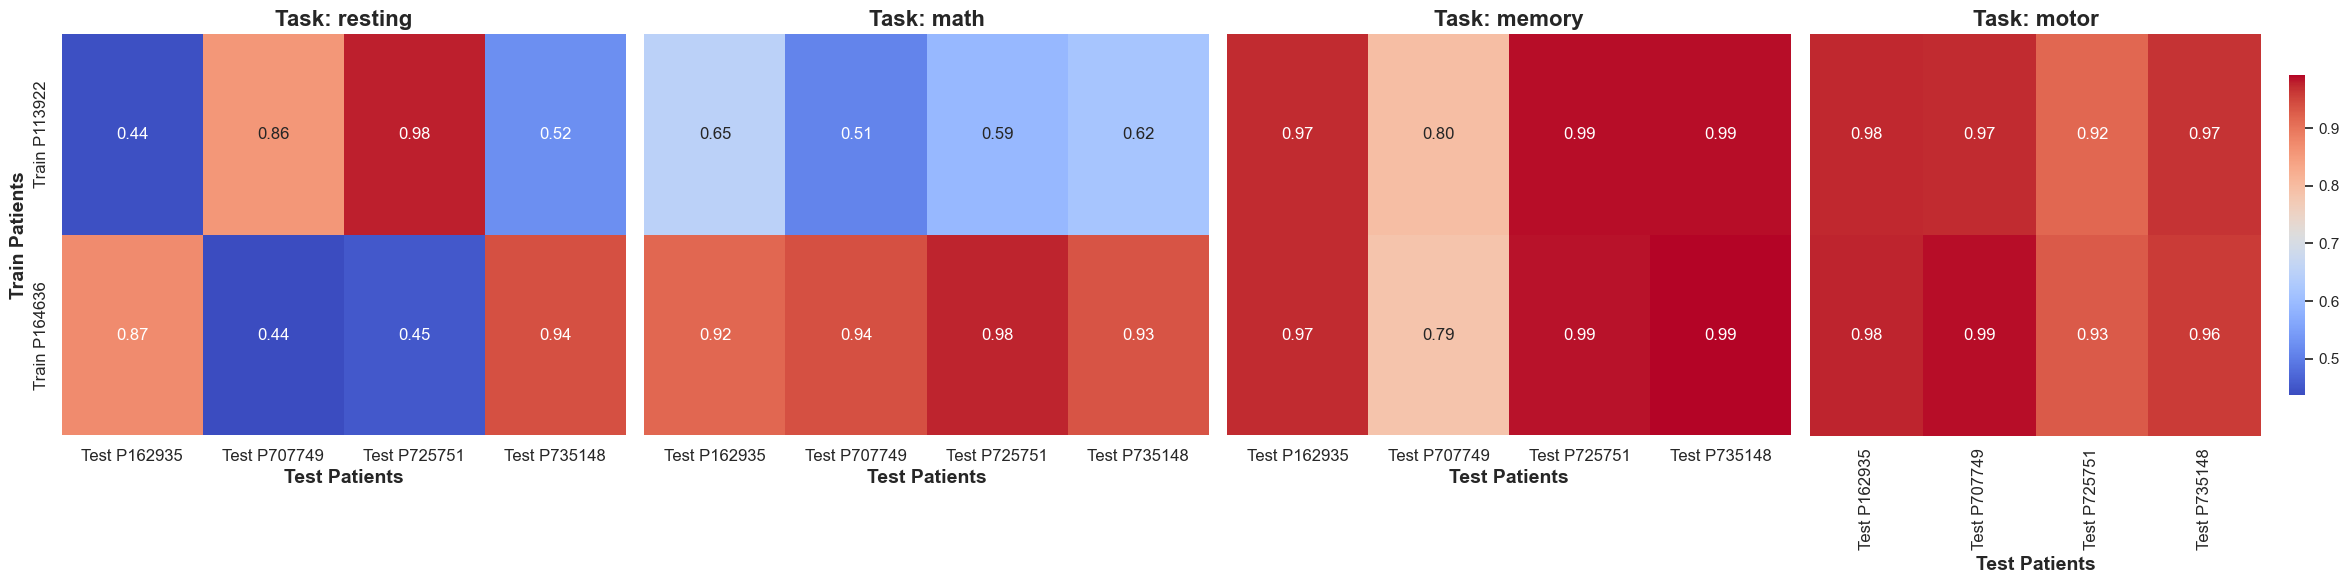

In [49]:
def plot_similarity_heatmaps_grouped_by_patient(train_data, test_data, train_df, test_df, task_types, similarity_metric="cosine"):
    """
    Plots heatmaps of similarity between train and test patients for each task type, grouped by patient_id.

    Args:
        train_data (torch.Tensor): Train data tensor of shape (N_train, C, T).
        test_data (torch.Tensor): Test data tensor of shape (N_test, C, T).
        train_df (pd.DataFrame): Train metadata DataFrame.
        test_df (pd.DataFrame): Test metadata DataFrame.
        task_types (list): List of task types (e.g., ["resting", "math", "memory", "motor"]).
        similarity_metric (str): Similarity metric to use ("cosine" or "correlation").
    """
    from sklearn.metrics.pairwise import cosine_similarity
    from scipy.stats import pearsonr

    # Convert PyTorch tensors to NumPy arrays
    train_data = train_data.numpy()
    test_data = test_data.numpy()

    # Calculate global min and max for the color bar
    global_min = float('inf')
    global_max = float('-inf')
    similarity_matrices = {}

    for task in task_types:
        # Filter train and test data by task type
        train_task_df = train_df[train_df["task_type"] == task]
        test_task_df = test_df[test_df["task_type"] == task]

        # Group by patient_id and average the data
        train_grouped = train_task_df.groupby("patient_id").apply(
            lambda group: train_data[group.index].mean(axis=0)
        )
        test_grouped = test_task_df.groupby("patient_id").apply(
            lambda group: test_data[group.index].mean(axis=0)
        )

        train_matrices = np.stack(train_grouped.values)
        test_matrices = np.stack(test_grouped.values)

        # Compute similarity matrix
        similarity_matrix = np.zeros((len(train_matrices), len(test_matrices)))
        for t_idx, train_matrix in enumerate(train_matrices):
            for te_idx, test_matrix in enumerate(test_matrices):
                if similarity_metric == "cosine":
                    similarity_matrix[t_idx, te_idx] = cosine_similarity(
                        train_matrix.reshape(1, -1), test_matrix.reshape(1, -1)
                    )[0, 0]
                elif similarity_metric == "correlation":
                    similarity_matrix[t_idx, te_idx] = pearsonr(
                        train_matrix.flatten(), test_matrix.flatten()
                    )[0]

        # Update global min and max
        global_min = min(global_min, similarity_matrix.min())
        global_max = max(global_max, similarity_matrix.max())

        # Store the similarity matrix for later use
        similarity_matrices[task] = (similarity_matrix, train_grouped.index, test_grouped.index)

    # Plot heatmaps
    fig, axes = plt.subplots(1, len(task_types), figsize=(6 * len(task_types), 6), sharey=True)
    if len(task_types) == 1:
        axes = [axes]  # Ensure axes is iterable for a single task type

    for i, task in enumerate(task_types):
        similarity_matrix, train_patient_ids, test_patient_ids = similarity_matrices[task]

        sns.heatmap(
            similarity_matrix,
            annot=True,  # Add value labels in each cell
            fmt=".2f",  # Format the labels to 2 decimal places
            cmap="coolwarm",
            vmin=global_min,  # Use global min for the color bar
            vmax=global_max,  # Use global max for the color bar
            xticklabels=[f"Test P{pid}" for pid in test_patient_ids],
            yticklabels=[f"Train P{pid}" for pid in train_patient_ids],
            ax=axes[i],
            cbar=i == len(task_types) - 1,  # Show colorbar only for the last plot
            cbar_kws={"shrink": 0.8}  # Adjust colorbar size
        )
        axes[i].set_title(f"Task: {task}", fontsize=16, fontweight="bold")
        axes[i].set_xlabel("Test Patients", fontsize=14, fontweight="bold")
        axes[i].set_ylabel("Train Patients" if i == 0 else "", fontsize=14, fontweight="bold")
        axes[i].tick_params(axis='x', labelsize=12)
        axes[i].tick_params(axis='y', labelsize=12)

    plt.tight_layout()
    plt.show()

# Call the updated function
plot_similarity_heatmaps_grouped_by_patient(train_data, test_data, train_df, test_df, task_types=task_types, similarity_metric="cosine")

C:\Users\bar24\AppData\Local\Temp\ipykernel_17212\1583943880.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cluster_colors = plt.cm.get_cmap("tab10", n_clusters)  # Use a colormap for clusters
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\

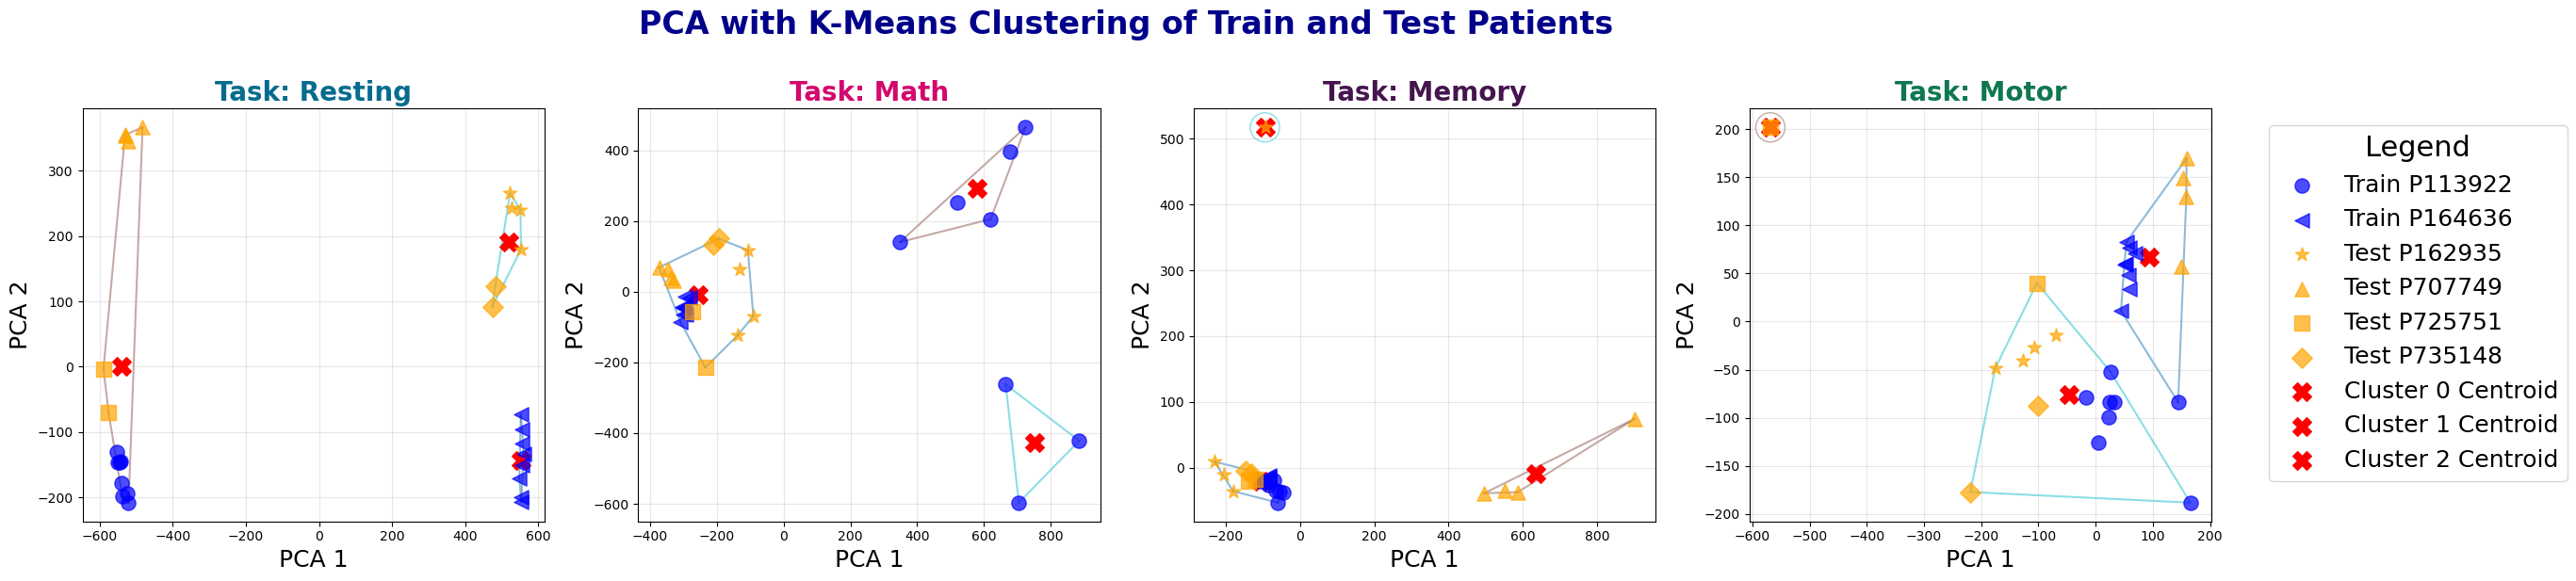

In [75]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.spatial import ConvexHull
import matplotlib.pyplot as plt
import numpy as np
import os

task_title_colors = ["#056c8e", "#d3086e", "#46154E", "#0e774f", "#494545"]

def plot_pca_with_clustering(train_data, test_data, train_df, test_df, task_types, n_clusters=3):
    """
    Plots PCA embeddings of train and test patient MEG data for each task type, using unique shapes for patient IDs,
    overlays k-means clustering results, and adds cluster boundaries.

    Args:
        train_data (np.ndarray): Train data tensor of shape (N_train, C, T).
        test_data (np.ndarray): Test data tensor of shape (N_test, C, T).
        train_df (pd.DataFrame): Train metadata DataFrame.
        test_df (pd.DataFrame): Test metadata DataFrame.
        task_types (list): List of task types (e.g., ["resting", "math", "memory", "motor"]).
        n_clusters (int): Number of clusters for k-means.
    """
    fig, axes = plt.subplots(1, len(task_types), figsize=(6 * len(task_types), 6))

    if len(task_types) == 1:
        axes = [axes]  # Ensure axes is iterable for a single task type

    # Define marker styles for patients
    # marker_styles = ['o', 's', 'D', '^', 'v', '<', '>', 'p', '*', 'h', 'H', 'X', 'd']
    marker_styles= ["o", "^", "<", "s", "D", "*"]
    cluster_colors = plt.cm.get_cmap("tab10", n_clusters)  # Use a colormap for clusters

    for i, task in enumerate(task_types):
        # Filter train and test data by task type
        train_indices = train_df[train_df["task_type"] == task].index
        test_indices = test_df[test_df["task_type"] == task].index

        # Extract patient IDs
        train_patient_ids = train_df.loc[train_indices, "patient_id"].values
        test_patient_ids = test_df.loc[test_indices, "patient_id"].values

        # Extract data for the current task
        train_matrices = train_data[train_indices].reshape(len(train_indices), -1)
        test_matrices = test_data[test_indices].reshape(len(test_indices), -1)

        # Combine train and test data
        all_data = np.vstack([train_matrices, test_matrices])
        labels = ["Train"] * len(train_matrices) + ["Test"] * len(test_matrices)
        patient_ids = list(train_patient_ids) + list(test_patient_ids)

        # Apply PCA
        pca = PCA(n_components=2)
        embeddings = pca.fit_transform(all_data)

        # Apply k-means clustering
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        cluster_labels = kmeans.fit_predict(embeddings)

        # Identify clusters with samples
        unique_clusters = np.unique(cluster_labels)

        # Plot PCA embeddings
        legend_entries = {}  # Track legend entries to avoid duplicates
        for label, color in zip(["Train", "Test"], ["blue", "orange"]):
            idx = [j for j, l in enumerate(labels) if l == label]
            for j in idx:
                marker = marker_styles[patient_ids[j] % len(marker_styles)]  # Assign marker based on patient ID
                if (label, patient_ids[j]) not in legend_entries:
                    axes[i].scatter(
                        embeddings[j, 0], embeddings[j, 1], label=f"{label} P{patient_ids[j]}",
                        alpha=0.7, color=color, marker=marker, zorder=3, s=120
                    )
                    legend_entries[(label, patient_ids[j])] = True
                else:
                    axes[i].scatter(
                        embeddings[j, 0], embeddings[j, 1],
                        alpha=0.7, color=color, marker=marker, zorder=3, s=120
                    )

        # Overlay cluster centroids for non-empty clusters
        for cluster in unique_clusters:
            cluster_points = embeddings[cluster_labels == cluster]
            cluster_center = kmeans.cluster_centers_[cluster]

            # Plot cluster centroid behind points
            axes[i].scatter(
                cluster_center[0], cluster_center[1],
                s=200, c='red', marker='X', label=f'Cluster {cluster} Centroid', zorder=2
            )

            # Add cluster boundaries
            if len(cluster_points) > 2:  # ConvexHull requires at least 3 points
                hull = ConvexHull(cluster_points)
                for simplex in hull.simplices:
                    axes[i].plot(cluster_points[simplex, 0], cluster_points[simplex, 1], color=cluster_colors(cluster), alpha=0.5, zorder=1)
            elif len(cluster_points) > 0:
                # Draw a circle around the cluster if there are fewer than 3 points
                axes[i].scatter(cluster_points[:, 0], cluster_points[:, 1], s=500, facecolors='none', edgecolors=cluster_colors(cluster), alpha=0.5, zorder=1)

        # Add clustering discussion elements
        task_title_color = task_title_colors[i]
        axes[i].set_title(f"Task: {task.capitalize()}", fontsize=20, fontweight="bold", color=task_title_color)
        axes[i].set_xlabel("PCA 1", fontsize=18)
        axes[i].set_ylabel("PCA 2", fontsize=18)
        axes[i].grid(alpha=0.3)

    # Add a single legend for all subplots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=18, title="Legend", title_fontsize=22)
    fig.suptitle("PCA with K-Means Clustering of Train and Test Patients", fontsize=24, fontweight="bold", color="darkblue", y=1.02)
    plt.tight_layout()
    plt.subplots_adjust(right=0.98)  # Adjust space for the legend
    plt.savefig(f"{output_dir}/pca_with_clustering.png", dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

# Suppress KMeans warnings by setting OMP_NUM_THREADS
os.environ["OMP_NUM_THREADS"] = "1"

# Example usage
# Assuming train_data and test_data are NumPy arrays and train_df/test_df are DataFrames
plot_pca_with_clustering(train_data, test_data, train_df, test_df, task_types=["resting", "math", "memory", "motor"], n_clusters=3)